In [2]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [3]:
plt.rcParams['figure.facecolor'] = 'w'
plt.rcParams['figure.edgecolor'] = 'k'

In [4]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [5]:
def critical_zone_only (star_data,print_star_cuts = True):
    c_zone_indices = []
    under_c_indices = []
    over_c_indices = []
    i = 0
    while i <len(np.transpose(star_data)):
        #print('logMdot = ',np.log10(star_data[MdotIndex][i]))
        #print('logMdotCrit = ',np.log10(star_data[MIndex][i]/(2*10**6)))
        if np.log10(star_data[MdotIndex][i]) <= np.log10(star_data[MIndex][i]/(2*10**6))-1: # 2*10**6 is the characteristic time for mass-loss (evolution time)
            i+=1
            under_c_indices.append(i)
        elif np.log10(star_data[MdotIndex][i]) >= np.log10(star_data[MIndex][i]/(2*10**6))+1:
            i+=1
            over_c_indices.append(i)
        else:
            c_zone_indices.append(i)
            i+=1
    trimmed_array = np.transpose(star_data)[c_zone_indices]
    if print_star_cuts == True:
        print(len(np.transpose(star_data))-len(c_zone_indices), 'stars cut.', len(trimmed_array), 'stars remaining.')
        print(len(over_c_indices), 'stars over the critical mass-loss rate.',len(under_c_indices), 'stars under the critical mass-loss rate.')
        print('_____')
    return np.transpose(trimmed_array)

def correct_mdot (star_data,multiplier):
    new_mdot_data = multiplier*star_data[MdotDustIndex]
    new_mdot_error_data = multiplier*star_data[MdotDustIndex+1]
    return np.asarray([star_data[0],star_data[1],star_data[2],star_data[3],star_data[4],new_mdot_data,new_mdot_error_data,star_data[7],star_data[8],star_data[9],star_data[10],star_data[11],star_data[12],star_data[13],star_data[14],star_data[15],star_data[16],star_data[17],star_data[18],star_data[19],star_data[20],star_data[21],star_data[22],star_data[23],star_data[24],star_data[25],star_data[26],star_data[27] ])

def find_max_crit_zone_multiplier (star_data, min_guess=1, max_guess = 10000):
    crit_zone_sizes_at_multiplier_value = []
    multiplier_values = []
    for multiplier in range(min_guess, max_guess):
        scaled_mdot_star_data = correct_mdot(star_data, multiplier)
        critical_zone_only_data = critical_zone_only (scaled_mdot_star_data, print_star_cuts = False)
        crit_zone_sizes_at_multiplier_value.append(len(np.transpose(critical_zone_only_data)))
        multiplier_values.append(multiplier)
    print ('Data maximized with',np.nanmax(crit_zone_sizes_at_multiplier_value),' stars with multiplier(s)', multiplier_values[np.argmax(crit_zone_sizes_at_multiplier_value)])
    return multiplier_values[np.argmax(crit_zone_sizes_at_multiplier_value)]

def linear_fit_1var (xdata, ydata):
    x = xdata
    y = ydata
    
    data = pandas.DataFrame({'x': x, 'y': y})
    model = ols("y ~ x", data).fit()
    # Parameters are returned in the format intercept, slope
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

def multilinear_fit_2var (xdata, ydata):
    x0 = xdata[0]
    x1 = xdata[1]
    y = ydata
    
    data = pandas.DataFrame({'x0': x0, 'x1': x1, 'y': y})
    model = ols("y ~ x0 + x1", data).fit()
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

# Check current multiplier
def check_gas_to_dust_ratio (star_data):
    star_by_star_ratio = star_data[MdotIndex]/star_data[MdotDustIndex]
    #print(star_by_star_ratio)
    print(np.nanmean(star_by_star_ratio))
    
def van_Loon_psi_for_non_solar (spec_type, solar_ratio, input_z):
    # Take spectral type (M or C), the solar ratio (dust-to-gas ratio for sun-like metallicity), intial metallicity z (divided by solar) for target, to find
    # dust-to-gas ratio for target metallicity
    if spec_type == 'M':
        # First, use the solar ratio to determine the constant in formula. Zsun ~ 0.0124
        constant = np.log10(solar_ratio) - 0.7*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (0.7 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (0.7 + 0.6)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((0.7- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((0.7+ 0.6)*np.log10(input_z)+constant_upper)
    elif spec_type == 'C':
        constant = np.log10(solar_ratio) - 1*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (1 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (1 + 0.3)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((1- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((1+ 0.3)*np.log10(input_z)+constant_upper)
    else:
        print('Error. Invalid Spectral Type.')
    return np.asarray([dtg_ratio_lower, dtg_ratio, dtg_ratio_upper])

In [6]:
ratios_M = (van_Loon_psi_for_non_solar('M',1/500,0.001/0.0124))**-1
ratios_C = (van_Loon_psi_for_non_solar('C',1/200,0.001/0.0124))**-1

M0StarData = correct_mdot (M0StarData, int(ratios_M[1]))
M1StarData = correct_mdot (M1StarData, int(ratios_M[1]))
C0StarData = correct_mdot (C0StarData, int(ratios_C[1]))
C1StarData = correct_mdot (C1StarData, int(ratios_C[1]))

# Mass-loss formulas (taken from All Necessary Fits - No Color Stuff.ipynb)

## O-rich (M)
### Fundamental:
#### Lower Bound:
##### delta logL, delta logM, delta logMdot: [0.20198361631524042, 0.11989668960937344, 1.6423545861871354]
##### log A, B, C: [-34.975963392304195, 8.131127742677283, -13.698081169196328]
#### Optimal:
##### delta logL, delta logM, delta logMdot: [0.20198361631524042, 0.11989668960937344, 1.6423545861871354]
##### log A, B, C: [-34.975963392304195, 8.131127742677283, -13.698081169196328]
#### Upper Bound:
##### delta logL, delta logM, delta logMdot: [0.5666080517902725, 0.33633633734749735, 1.886056647693164]
##### log A, B, C: [-18.13441585975965, 3.3286795726497718, -5.607650551728879]

### First-Overtone:
#### Lower Bound:
##### delta logL, delta logM, delta logMdot: [0.11188624038760686, 0.05548014652936273, 1.8159398112730436]
##### log A, B, C: [-64.52710704694141, 16.230233538834568, -32.7313449021257]
#### Optimal:
##### delta logL, delta logM, delta logMdot: [0.1891101235031245, 0.09377254366392473, 1.9199034860015933]
##### log A, B, C: [-42.82979371999287, 10.152304120143375, -20.474047210262466]
#### Upper Bound:
##### delta logL, delta logM, delta logMdot: [0.6712950650780005, 0.3328697831470864, 2.0150637464358763]
##### log A, B, C: [-17.30338823114128, 3.001755638113827, -6.053609695012397]

## C-rich (C)
### Fundamental:
#### Lower Bound:
##### delta logL, delta logM, delta logMdot: [0.05735936786466267, 0.03973053351846678, 1.40823996531185]
##### log A, B, C: [-94.20685284118863, 24.551176516354587, -35.444778627432704]
#### Optimal:
##### delta logL, delta logM, delta logMdot: [0.19548072568275332, 0.13540165823092454, 1.8834944309285628]
##### log A, B, C: [-41.078937026141794, 9.635192545710597, -13.910423664947327]
#### Upper Bound:
##### delta logL, delta logM, delta logMdot: [0.34414473531462164, 0.238375255004252, 2.0248235837250323]
##### log A, B, C: [-27.716614374612355, 5.883639573547193, -8.494269187835435]

### First-Overtone:
#### Lower Bound:
##### delta logL, delta logM, delta logMdot: [0.08464344595018058, 0.05278120333695352, 1.2833012287035501]
##### log A, B, C: [-61.55486794571157, 15.16125925991807, -24.31360309296088]
#### Optimal:
##### delta logL, delta logM, delta logMdot: [0.19474764044216197, 0.12143899263765517, 1.1461280356782382]
##### log A, B, C: [-28.14202038380528, 5.88519600584648, -9.437891494192556]
#### Upper Bound:
##### delta logL, delta logM, delta logMdot: [0.5078437470122208, 0.31667666378125925, 1.4507923159973135]
##### log A, B, C: [-17.23347391118014, 2.856769084059238, -4.581304787900101]

In [7]:
def calc_mdot_from_formula_LM (logA, B, C, L, M):
    # Given values for logA, B, and C, calculate a mass-loss rate logMdot. Independent variables are
    # L and M, and should be numpy array-like valuee (includes individual floats). Returns either a single
    # value (L and M are floats), an array-like list (only one of L and M is a float, the other is array-like)
    # or an array-like matrix (n x m list of lists when L is length n and M is length m).
    if type(L) == float and type(M) == float: # 2 floats
        logMdot = logA + B*np.log10(L) + C*np.log10(M)
    elif len(L) > 1 and len(M) > 1: # 2 lists
        n = len(L)
        m = len(M)
        logMdot = np.zeros((n, m))
        for i in range(0, n):
            for k in range(0, m):
                logMdot_value = logA + B*np.log10(L[i]) + C*np.log10(M[k])
                logMdot[i,k] = logMdot_value
    else: # 1 list, 1 float
        if type(L) == float:
            m = len(M)
            logMdot = np.zeros(m)
            for k in range(0, m):
                logMdot_value = logA + B*np.log10(L) + C*np.log10(M[k])
                logMdot[k] = logMdot_value
        if type(M) == float:
            n = len(L)
            logMdot = np.zeros(n)
            for i in range(0, n):
                logMdot_value = logA + B*np.log10(L[i]) + C*np.log10(M)
                logMdot[i] = logMdot_value
    return logMdot

In [8]:
M0_logA_B_C = [-34.975963392304195, 8.131127742677283, -13.698081169196328]
M1_logA_B_C = [-42.82979371999287, 10.152304120143375, -20.474047210262466]
C0_logA_B_C = [-41.078937026141794, 9.635192545710597, -13.910423664947327]
C1_logA_B_C = [-28.14202038380528, 5.88519600584648, -9.437891494192556]

M_Grid = [0.7, 1.0, 1.4, 2.0]
L_Grid = np.arange(500,50001,100)
#print(L_Grid)
M0_logMdot = np.transpose(calc_mdot_from_formula_LM (M0_logA_B_C[0], M0_logA_B_C[1], M0_logA_B_C[2],L_Grid,M_Grid ))
M1_logMdot = np.transpose(calc_mdot_from_formula_LM (M1_logA_B_C[0], M1_logA_B_C[1], M1_logA_B_C[2],L_Grid,M_Grid ))
C0_logMdot = np.transpose(calc_mdot_from_formula_LM (C0_logA_B_C[0], C0_logA_B_C[1], C0_logA_B_C[2],L_Grid,M_Grid ))
C1_logMdot = np.transpose(calc_mdot_from_formula_LM (C1_logA_B_C[0], C1_logA_B_C[1], C1_logA_B_C[2],L_Grid,M_Grid ))
#print(M0_logMdot)

In [9]:
M0_logMdot[0]

array([-1.09084339e+01, -1.02646011e+01, -9.72024817e+00, -9.24870824e+00,
       -8.83278054e+00, -8.46072054e+00, -8.12415133e+00, -7.81688772e+00,
       -7.53423259e+00, -7.27253482e+00, -7.02890002e+00, -6.80099489e+00,
       -6.58691093e+00, -6.38506719e+00, -6.19413941e+00, -6.01300719e+00,
       -5.84071430e+00, -5.67643798e+00, -5.51946530e+00, -5.36917437e+00,
       -5.22501950e+00, -5.08651924e+00, -4.95324667e+00, -4.82482147e+00,
       -4.70090335e+00, -4.58118667e+00, -4.46539584e+00, -4.35328154e+00,
       -4.24461746e+00, -4.13919758e+00, -4.03683377e+00, -3.93735385e+00,
       -3.84059974e+00, -3.74642606e+00, -3.65469872e+00, -3.56529384e+00,
       -3.47809673e+00, -3.39300095e+00, -3.30990761e+00, -3.22872463e+00,
       -3.14936615e+00, -3.07175195e+00, -2.99580700e+00, -2.92146102e+00,
       -2.84864805e+00, -2.77730615e+00, -2.70737705e+00, -2.63880589e+00,
       -2.57154093e+00, -2.50553332e+00, -2.44073694e+00, -2.37710812e+00,
       -2.31460553e+00, -

In [10]:
def logMdot_vs_logL (M_grid, L_grid, logMdot_grids,formula_defines,t_ev=2000000):
    type_labels = ['M0', 'M1', 'C0', 'C1']
    linestyle_list = ['-','--',':','-.']
    color_list = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown','tab:pink', 'tab:gray', 'tab:olive','tab:cyan']
    for i in range(0, len(logMdot_grids)):
        for k in range(0, len(logMdot_grids[i])):
            line_label = type_labels[i] + ' -- ' + 'M=' + str(M_grid[k])
            plot.plot(np.log10(L_Grid),logMdot_grids[i][k],color=color_list[i],linestyle=linestyle_list[k],label=line_label)
    # Mdot crit lines
    for i in range(0, len(M_grid)):
        logMdot_crit = np.log10(M_grid[i]/t_ev)
        for k in range(0, len(formula_defines)):
            #print(formula_defines[k])
            logA = formula_defines[k][0]
            B = formula_defines[k][1]
            C = formula_defines[k][2]
            if k == 0:
                logL_min = (-logA - C*np.log10(M_grid[i]) + (-8))/B
                logL_max = (-logA - C*np.log10(M_grid[i]) + (-4))/B
            if k > 0:
                logL_min_comp = (-logA - C*np.log10(M_grid[i]) + (-8))/B
                if logL_min > logL_min_comp:
                    logL_min = (-logA - C*np.log10(M_grid[i]) + (-8))/B
                    #print('logL_min > logL_min_comp True')
                logL_max_comp = (-logA - C*np.log10(M_grid[i]) + (-4))/B
                if logL_max < logL_max_comp:
                    logL_max = (-logA - C*np.log10(M_grid[i]) + (-4))/B
                    #print('logL_max < logL_max_comp True')
        print(logL_min, logL_max)
        plot.plot([logL_min,logL_max],[logMdot_crit,logMdot_crit],color='k',linestyle=linestyle_list[i])
    plot.ylim(-8, -4)
    plot.legend(loc=5,bbox_to_anchor=(1.7,0.5),ncol=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log \dot{M}$')
    plot.show()

3.0566613337903776 3.85374972570008
3.317616479042303 4.102160804809573
3.5637906577247596 4.336501435711354
3.824745802976686 4.584912514820847


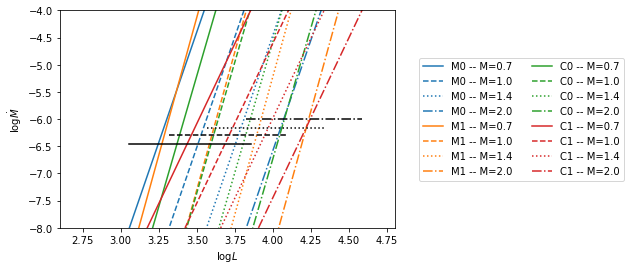

In [11]:
logMdot_vs_logL (M_Grid, L_Grid, [M0_logMdot, M1_logMdot, C0_logMdot, C1_logMdot],[M0_logA_B_C, M1_logA_B_C, C0_logA_B_C, C1_logA_B_C])

In [12]:
M_Grid = np.asarray([0.5, 0.7, 1.0, 1.2, 1.4, 1.7, 2.0, 2.2])
M_Grid = np.arange(0.3,3.0,0.05)

In [13]:
def cliff_plot (M_grid, formula_defines,t_ev=2000000,star_data=[]):
    type_labels = ['M0', 'M1', 'C0', 'C1']
    linestyle_list = ['-','--',':','-.']
    color_list = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown','tab:pink', 'tab:gray', 'tab:olive','tab:cyan']
    Mdot_crit_grid = M_grid/t_ev
    
    
    for i in range(0, len(formula_defines)):
        logA = formula_defines[i][0]
        B = formula_defines[i][1]
        C = formula_defines[i][2]
        logL_crit_grid = (-logA - C*np.log10(M_grid) + np.log10(Mdot_crit_grid))/B
        cliff_label = type_labels[i]
        plot.plot(logL_crit_grid, M_grid,color=color_list[i],label=cliff_label)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$M$')
    plot.legend()
    plot.show()
    
    for i in range(0, len(formula_defines)):
        logA = formula_defines[i][0]
        B = formula_defines[i][1]
        C = formula_defines[i][2]
        logL_crit_grid = (-logA - C*np.log10(M_grid) + np.log10(Mdot_crit_grid))/B
        cliff_label = type_labels[i]
        plot.plot(logL_crit_grid, np.log10(M_grid),color=color_list[i],label=cliff_label)
    if len(star_data)>0:
        for i in range(0, len(star_data)):
            cliff_label = type_labels[i]
            plot.scatter(np.log10(star_data[i][LIndex]),np.log10(star_data[i][MIndex]),label=cliff_label,alpha=0.25,s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    plot.legend()
    plot.show()

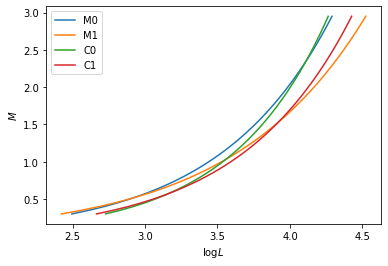

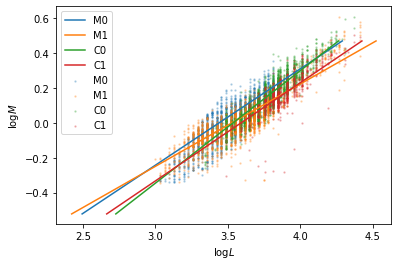

In [14]:
cliff_plot(M_Grid,[M0_logA_B_C, M1_logA_B_C, C0_logA_B_C, C1_logA_B_C],t_ev=10e6,star_data=[M0StarData, M1StarData, C0StarData, C1StarData] )

In [17]:
np.sort(M0StarData[MIndex])[int(len(M0StarData[MIndex])*.9)]

1.3988161960631489

In [22]:
logM_Grid = np.arange(-0.3,0.4,0.05)
M_Grid = 10**logM_Grid

In [25]:
def cliff_plot_percentile_limits(M_grid, formula_defines,t_ev=2000000,star_data=[],lower_percentile = 10, upper_percentile = 90,other_percentiles =[]):
    type_labels = ['M0', 'M1', 'C0', 'C1']
    linestyle_list = ['-','--',':','-.']
    color_list = ['tab:blue', 'tab:green',  'tab:orange','tab:red', 'tab:purple', 'tab:brown','tab:pink', 'tab:gray', 'tab:olive','tab:cyan']
    Mdot_crit_grid = M_grid/t_ev
    
    for i in range(0, len(formula_defines)):
        logA = formula_defines[i][0]
        B = formula_defines[i][1]
        C = formula_defines[i][2]
        logL_crit_grid = (-logA - C*np.log10(M_grid) + np.log10(Mdot_crit_grid))/B
        cliff_label = type_labels[i]
        lower_percentile_cut = np.sort(star_data[i][MIndex])[int(len(star_data[i][MIndex])*lower_percentile/100)]
        upper_percentile_cut = np.sort(star_data[i][MIndex])[int(len(star_data[i][MIndex])*upper_percentile/100)]
        if len (other_percentiles) > 0:
            other_percentiles = np.asarray(other_percentiles)
            other_percentiles = np.sort(star_data[i][MIndex])[int(len(star_data[i][MIndex])*other_percentiles/100)]
        percentile_masses = [lower_percentile_cut]
        if len (other_percentiles) > 0:
            for k in range (0,len(other_percentiles)):
                percentile_masses.append(other_percentiles[k])
        percentile_masses.append(upper_percentile_cut)
        percentile_masses = np.asarray(percentile_masses)
        Mdot_crit_percentiles_grid = percentile_masses/t_ev
        logL_percentiles_crit_grid = (-logA - C*np.log10(percentile_masses) + np.log10(Mdot_crit_percentiles_grid))/B
        plot.plot(logL_crit_grid, np.log10(M_grid),color=color_list[i],linestyle=linestyle_list[1],alpha=0.3)
        plot.plot(logL_percentiles_crit_grid, np.log10(percentile_masses),color=color_list[i],label=cliff_label,linestyle=linestyle_list[0])
        plot.scatter(logL_percentiles_crit_grid,np.log10(percentile_masses),color=color_list[i],marker='o',s=10)
        
        
        
    #if len(star_data)>0:
    #    for i in range(0, len(star_data)):
    #        cliff_label = type_labels[i]
    #        plot.scatter(np.log10(star_data[i][LIndex]),np.log10(star_data[i][MIndex]),label=cliff_label,alpha=0.25,s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    plot.legend()
    plot.show()

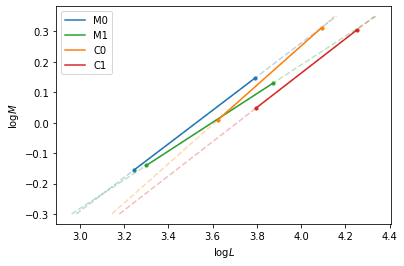

In [26]:
cliff_plot_percentile_limits(M_Grid,[M0_logA_B_C, M1_logA_B_C, C0_logA_B_C, C1_logA_B_C],star_data=[M0StarData, M1StarData, C0StarData, C1StarData] )